# hw2: Решающие деревья

*Спасибо великому курсу великого Евгения Соколова*

### О задании

Задание состоит из двух разделов:
1. В первом разделе вы научитесь применять деревья из sklearn для задачи классификации. Вы посмотрите какие разделяющие поверхности деревья строят для различных датасетов и проанализируете их зависимость от различных гиперпараметров.
2. Во втором разделе вы попробуете реализовать свое решающее дерево и сравните его со стандартное имплементацией из sklearn. Вы также протестируете деревья на более сложных датасетах и сравните различные подходы к кодированию категориальных признаков.

Все данные, на которых будут обучаться модели, вы можете найти на диске.

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов. Неэффективная и/или неоригинальная реализация кода может негативно отразиться на оценке.

### Формат сдачи
Заполненный ноутбук ```hw2-trees.ipynb``` и модуль с реализованными функциями и классами ```hw2code.py``` необходимо загрузить на свой Github. Затем нужно оставить комментарий в Google-таблице с оценками в столбце <<hw2>> в строке со своей фамилией о том, что вы выполнили работу с указанием ника на Kaggle. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from matplotlib.colors import Colormap, ListedColormap
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
sns.set(style='whitegrid')

import warnings
warnings.filterwarnings('ignore')

# 1. Решающие деревья. Визуализация.

В этой части мы рассмотрим два простых двумерных датасета сделанных с помощью `make_moons`, `make_circles` и посмотрим как ведет себя разделяющая поверхность в зависимости от различных гиперпараметров.

In [2]:
from sklearn.datasets import make_moons, make_circles, make_classification
datasets = [
    make_circles(noise=0.2, factor=0.5, random_state=42),
    make_moons(noise=0.2, random_state=42),
    make_classification(n_classes=3, n_clusters_per_class=1, n_features=2, class_sep=.8, random_state=3,
                        n_redundant=0, )
]

In [3]:
palette = sns.color_palette(n_colors=3)
cmap = ListedColormap(palette)

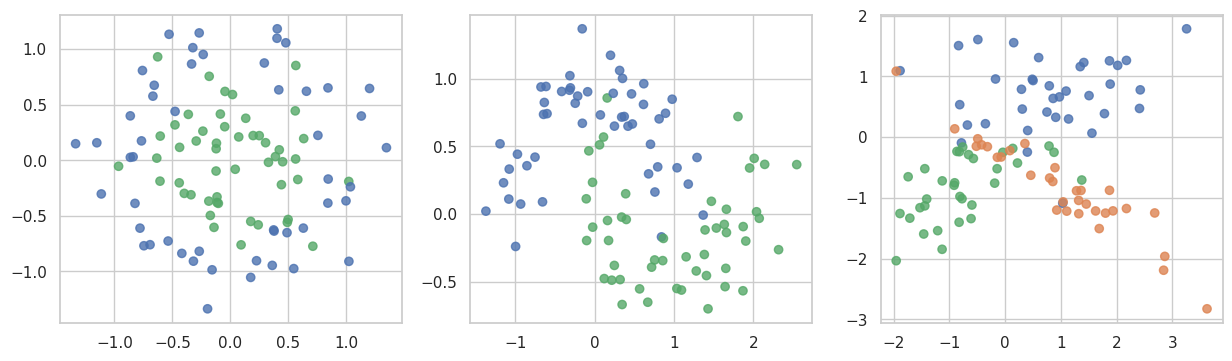

In [4]:
plt.figure(figsize=(15, 4))
for i, (x, y) in enumerate(datasets):
    plt.subplot(1, 3, i + 1)
    plt.scatter(x[:, 0], x[:, 1], c=y, cmap=cmap, alpha=.8)

__Задание 1. (1 балл)__

Для каждого датасета обучите решающее дерево с параметрами по умолчанию, предварительно разбив выборку на обучающую и тестовую. Постройте разделящие поверхности (для этого воспользуйтесь функцией `plot_surface`, пример ниже). Посчитайте accuracy на обучающей и тестовой выборках. Сильно ли деревья переобучились?

In [5]:
def plot_surface(clf, X, y):
    plot_step = 0.01
    palette = sns.color_palette(n_colors=len(np.unique(y)))
    cmap = ListedColormap(palette)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, cmap=cmap, alpha=0.3)

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, alpha=.7,
                edgecolors=np.array(palette)[y], linewidths=2)

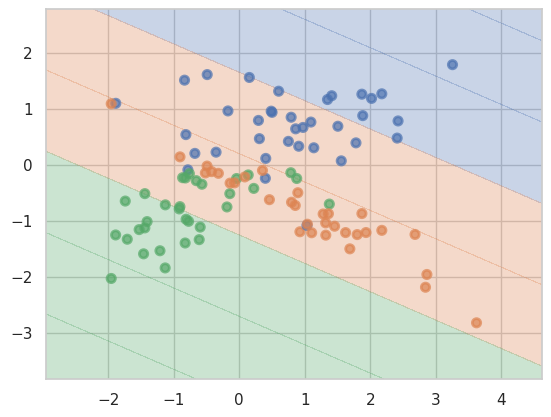

In [6]:
# Пример:
from sklearn.linear_model import LinearRegression
X, y = datasets[2]
lr  = LinearRegression().fit(X, y)
plot_surface(lr, X, y)

Круги — train 100.00%, test 80.00%
Полумесяцы — train 100.00%, test 96.00%
Три класса — train 100.00%, test 76.00%


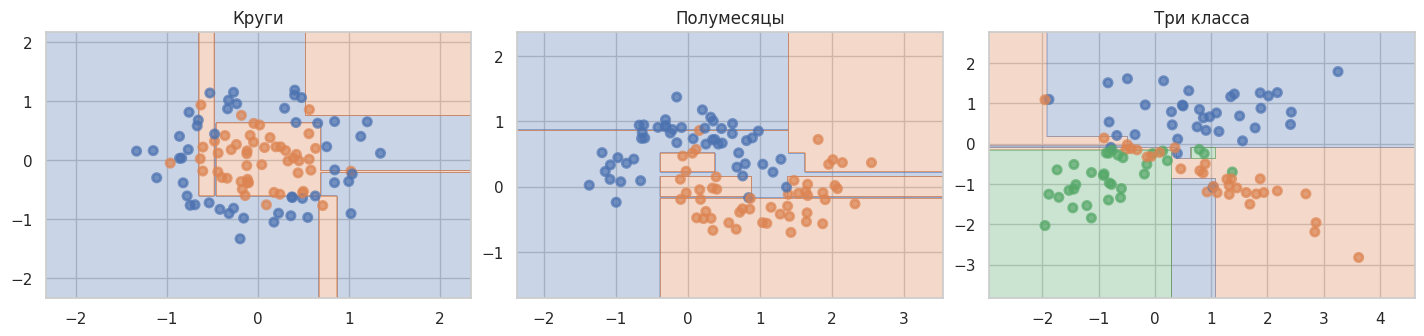

In [7]:
names = ["Круги", "Полумесяцы", "Три класса"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name, (X, y) in zip(axes, names, datasets):
    xTrain, xTest, yTrain, yTest = train_test_split(
        X, y, test_size=0.25, random_state=42, stratify=y
    )

    tree = DecisionTreeClassifier(random_state=42)
    tree.fit(xTrain, yTrain)

    trainAccuracy = tree.score(xTrain, yTrain)
    testAccuracy = tree.score(xTest, yTest)
    print(f"{name} — train {trainAccuracy:.2%}, test {testAccuracy:.2%}")

    plt.sca(ax)
    plot_surface(tree, X, y)
    ax.set_title(name)

plt.show()

__Ответ:__

На всех трёх наборах дерево правильно классифицировало все обучающие точки. На тесте качество снизилось сильнее всего для набора с тремя классами и для кругов. Такой разрыв указывает на переобучение. На полумесяцах дерево ошиблось только на одной тестовой точке, поэтому на этом разбиении переобучение заметно слабее. В каждой тестовой части всего 25 точек, поэтому одна ошибка меняет accuracy на четыре процентных пункта.

__Задание 2. (1.5 балла)__

Попробуйте перебрать несколько параметров для регуляризации (напр. `max_depth`, `min_samples_leaf`). Для каждого набора гиперпараметров постройте разделяющую поверхность, выведите обучающую и тестовую ошибки. Можно делать кросс-валидацию или просто разбиение на трейн и тест, главное делайте каждый раз одинаковое разбиение, чтобы можно было корректно сравнивать (помните же, что итоговое дерево сильно зависит от небольшого изменения обучающей выборки?). Проследите как меняется разделяющая поверхность и обобщающая способность. Почему так происходит, одинаково ли изменение для разных датасетов?

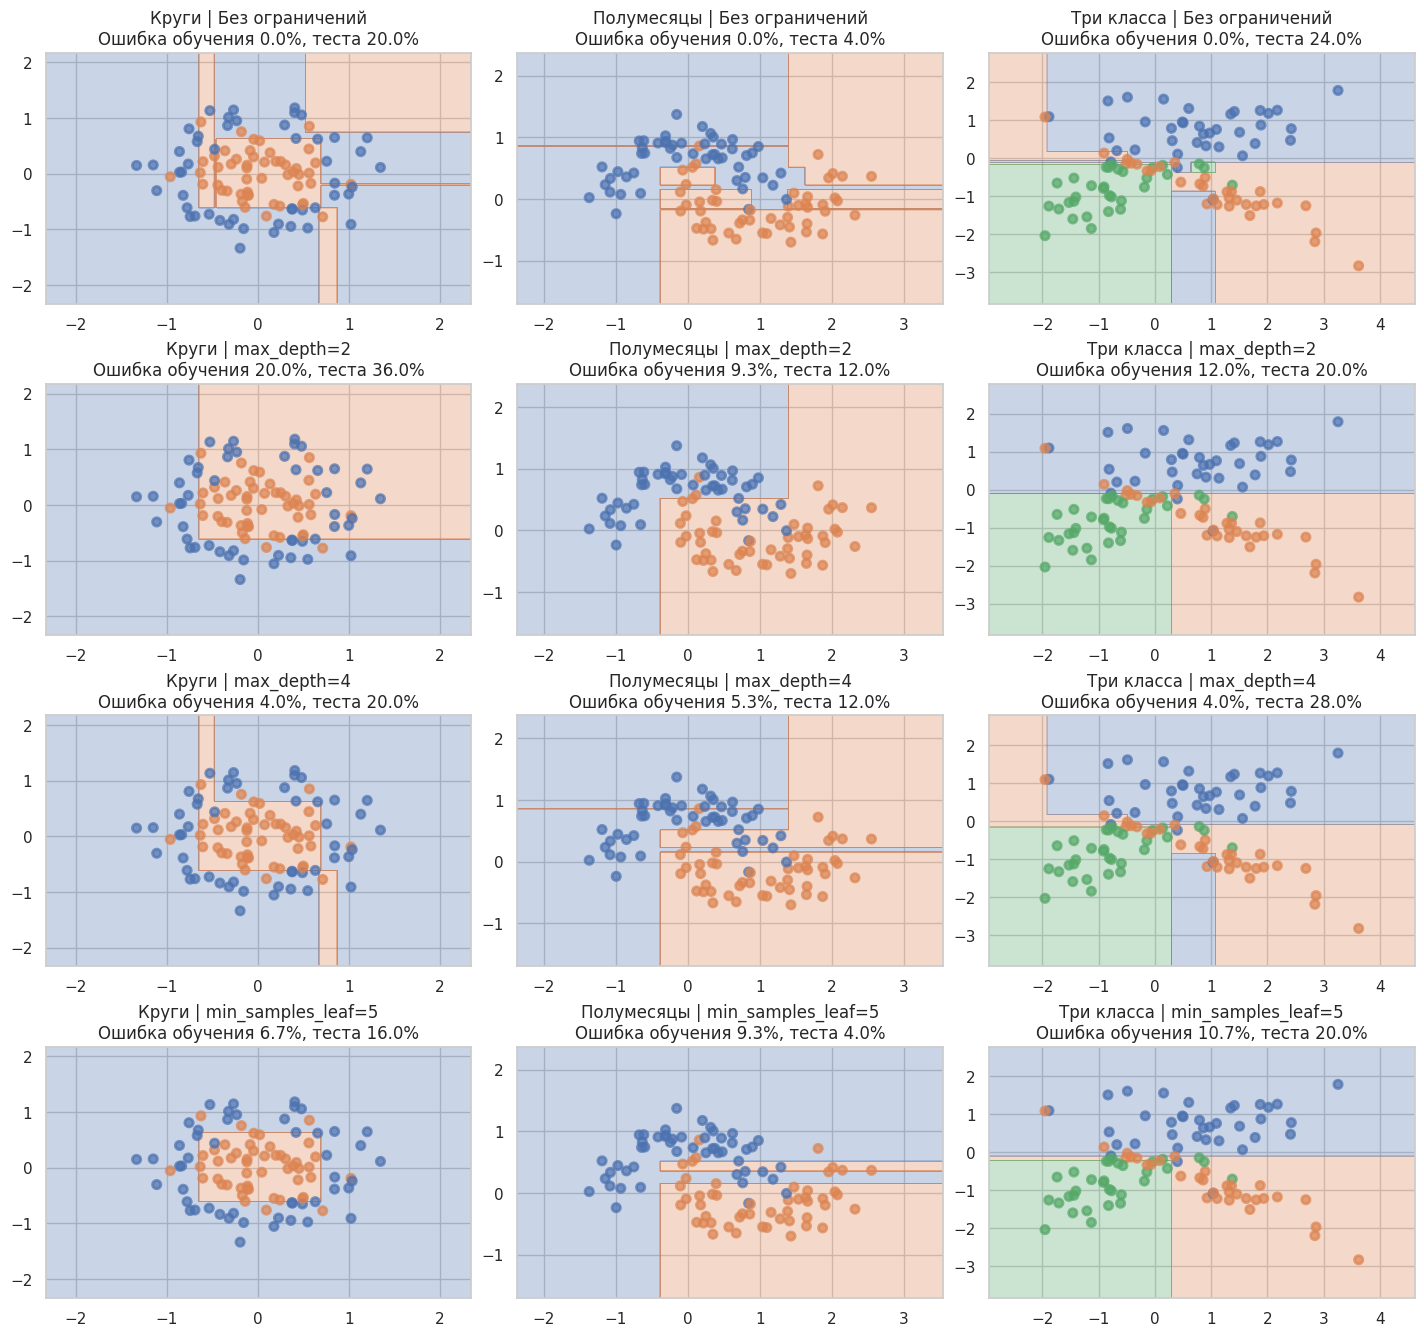

In [8]:
names = ["Круги", "Полумесяцы", "Три класса"]

settings = [
    ("Без ограничений", {}),
    ("max_depth=2", {"max_depth": 2}),
    ("max_depth=4", {"max_depth": 4}),
    ("min_samples_leaf=5", {"min_samples_leaf": 5}),
]

splits = [
    train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
    for X, y in datasets
]

fig, axes = plt.subplots(len(settings), len(datasets), figsize=(15, 14))

for row, (label, params) in enumerate(settings):
    for col, (X, y) in enumerate(datasets):
        xTrain, xTest, yTrain, yTest = splits[col]

        tree = DecisionTreeClassifier(random_state=42, **params)
        tree.fit(xTrain, yTrain)

        trainError = 1 - tree.score(xTrain, yTrain)
        testError = 1 - tree.score(xTest, yTest)

        ax = axes[row, col]
        plt.sca(ax)
        plot_surface(tree, X, y)
        ax.set_title(
            f"{names[col]} | {label}\n"
            f"Ошибка обучения {trainError:.1%}, теста {testError:.1%}"
        )

plt.show()

__Ответ:__

Ограничения делают границу проще и убирают часть мелких областей. Для кругов глубины 2 оказалось мало. Дерево делало слишком мало разрезов, чтобы хорошо отделить внутренний круг от внешнего. При min_samples_leaf=5 ошибка на обучении выросла, а ошибка на тесте снизилась с 20% до 16%. Для полумесяцев это же ограничение сохранило тестовую ошибку в 4%. Для трёх классов глубина 2 дала 20% ошибок на тесте, а глубина 4 — 28%. Значит, большая глубина может улучшить качество на обучении и одновременно ухудшить его на новых точках. В каждом тесте всего 25 точек, поэтому разница в 4 процентных пункта соответствует одной точке.

# 2. Решающие деревья своими руками

В этой части вам нужно реализовать свой класс для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

__Задание 3. (1.5 балл)__

Реализуйте функцию find_best_split из модуля hw2code.py

✅

__Задание 4. (0.5 балла)__

Загрузите таблицу students.csv (это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling)). В ней признаки объекта записаны в первых пяти столбцах, а в последнем записана целевая переменная (класс: 0 или 1). Постройте на одном изображении пять кривых "порог — значение критерия Джини" для всех пяти признаков. Отдельно визуализируйте scatter-графики "значение признака — класс" для всех пяти признаков.

STG — порог 0.615, Q = -0.4540
SCG — порог 0.425, Q = -0.4650
STR — порог 0.365, Q = -0.4673
LPR — порог 0.390, Q = -0.4547
PEG — порог 0.335, Q = -0.0861


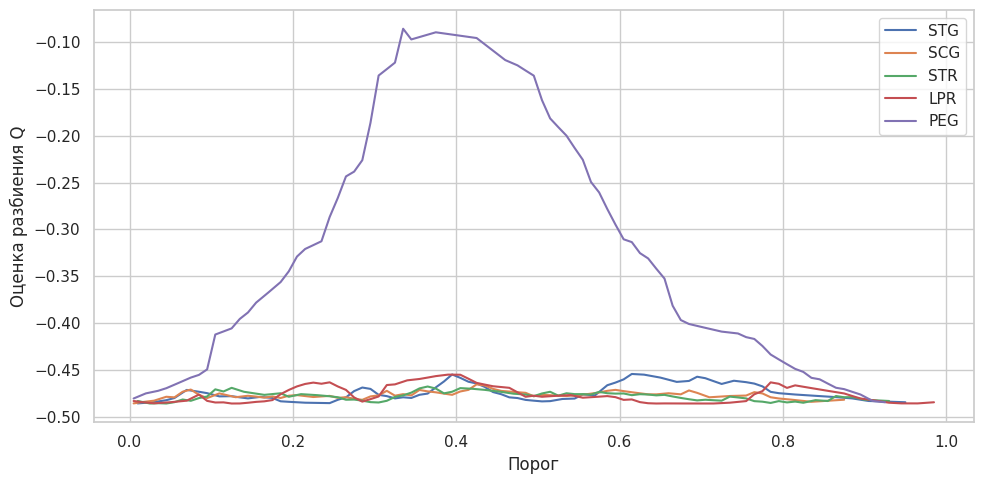

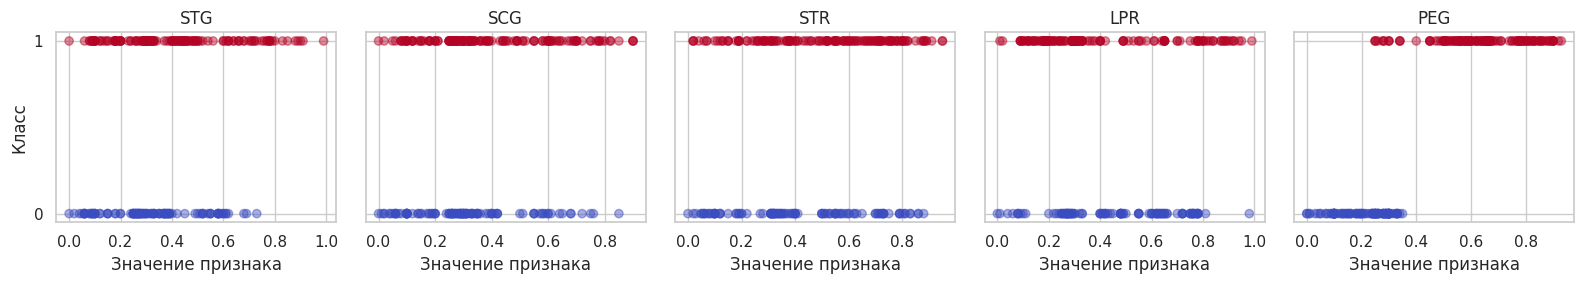

In [9]:
from hw2code import find_best_split

students = pd.read_csv("datasets/students.csv")
features = students.iloc[:, :5]
classes = students.iloc[:, -1].to_numpy()

fig, giniAx = plt.subplots(figsize=(10, 5))

scatterFig, scatterAxes = plt.subplots(
    1, features.shape[1], figsize=(16, 3), sharey=True
)

for featureName, scatterAx in zip(features.columns, scatterAxes):
    values = features[featureName].to_numpy()

    thresholds, ginis, bestThreshold, bestGini = find_best_split(values, classes)
    giniAx.plot(thresholds, ginis, label=featureName)

    scatterAx.scatter(values, classes, c=classes, cmap="coolwarm", alpha=0.45)
    scatterAx.set_title(featureName)
    scatterAx.set_xlabel("Значение признака")

    print(f"{featureName} — порог {bestThreshold:.3f}, Q = {bestGini:.4f}")

giniAx.set_xlabel("Порог")
giniAx.set_ylabel("Оценка разбиения Q")
giniAx.legend()
fig.tight_layout()

scatterAxes[0].set_ylabel("Класс")
scatterAxes[0].set_yticks([0, 1])
scatterFig.tight_layout()

plt.show()

__Задание 5. (0.5 балла)__

Исходя из кривых значений критерия Джини, по какому признаку нужно производить деление выборки на два поддерева? Согласуется ли этот результат с визуальной оценкой scatter-графиков? Как бы охарактеризовали вид кривой для "хороших" признаков, по которым выборка делится почти идеально? Чем отличаются кривые для признаков, по которым деление практически невозможно?

**Ответ:**

Первое разбиение нужно сделать по признаку PEG с порогом 0.335, потому что этот порог даёт максимальное значение критерия Q. Это согласуется с диаграммой рассеяния. Слева от порога большинство объектов относится к классу 0, а справа — к классу 1.

У хорошего признака есть порог или диапазон порогов, где кривая поднимается близко к нулю. Это значит, что после разбиения обе группы почти однородны. У слабого признака даже максимум остаётся далеко от нуля. Кривая может немного колебаться, но ни один порог не разделяет классы достаточно хорошо.

__Задание 6. (1.5 балла).__

Разберитесь с уже написанным кодом в классе DecisionTree модуля hw2code.py. Найдите ошибки в реализации метода \_fit_node. Напишите функцию \_predict_node.

 Построение дерева осуществляется согласно базовому жадному алгоритму, предложенному в лекции. Выбор лучшего разбиения необходимо производить по критерию Джини. Критерий останова: все объекты в листе относятся к одному классу или ни по одному признаку нельзя разбить выборку. Ответ в листе: наиболее часто встречающийся класс в листе. Для категориальных признаков выполняется преобразование, описанное в лекции в разделе «Учет категориальных признаков».

__Задание 7. (0.5 балла)__

Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Вам нужно скачать таблицу agaricus-lepiota.data (лежит на гитхабе вместе с заданием), прочитать ее с помощью pandas, применить к каждому столбцу LabelEncoder (из sklearn), чтобы преобразовать строковые имена категорий в натуральные числа. Первый столбец — это целевая переменная (e — edible, p — poisonous) Мы будем измерять качество с помощью accuracy, так что нам не очень важно, что будет классом 1, а что — классом 0. Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные) и сделайте предсказания для оставшейся половины. Вычислите accuracy.

У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [10]:
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

from hw2code import DecisionTree

mushrooms = pd.read_csv("datasets/agaricus-lepiota.data", header=None)

X = mushrooms.iloc[:, 1:].apply(
    lambda column: LabelEncoder().fit_transform(column)
).to_numpy()
y = LabelEncoder().fit_transform(mushrooms.iloc[:, 0])

xTrain, xTest, yTrain, yTest = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=y
)

tree = DecisionTree(feature_types=["categorical"] * X.shape[1])
tree.fit(xTrain, yTrain)
predictions = tree.predict(xTest)

print(f"Обучение — {len(yTrain)} объектов")
print(f"Тест — {len(yTest)} объектов")
print(f"Accuracy — {accuracy_score(yTest, predictions):.4f}")
print(f"Ошибок — {(predictions != yTest).sum()}")


Обучение — 4062 объектов
Тест — 4062 объектов
Accuracy — 1.0000
Ошибок — 0


__Задание 8. (бонус, 1 балл)__

Реализуйте в классе DecisionTree поддержку параметров max_depth, min_samples_split и min_samples_leaf по аналогии с DecisionTreeClassifier. Постройте графики зависимости качества предсказания в зависимости от этих параметров для набора данных tic-tac-toe (см. следующий пункт).

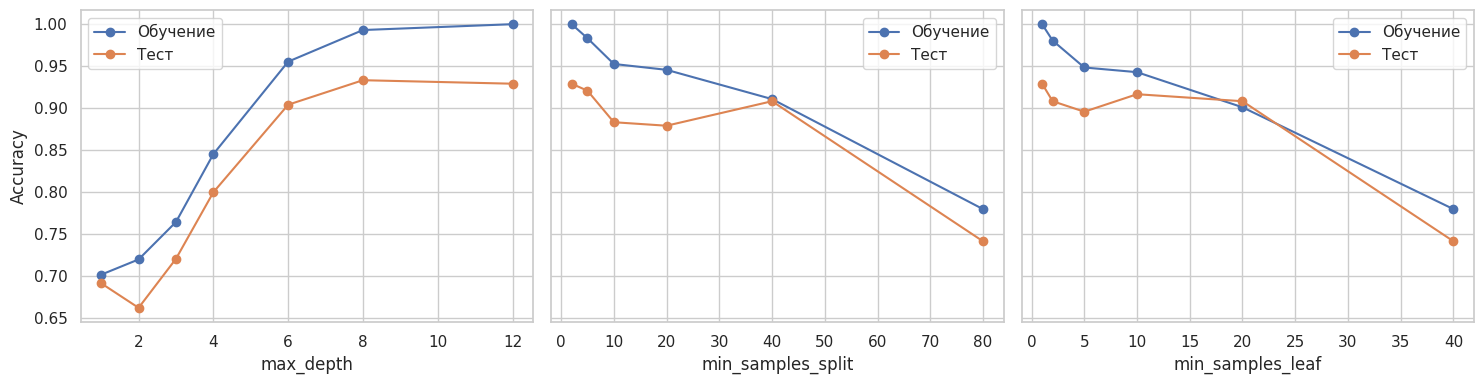

In [13]:
import importlib
import hw2code

from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

importlib.reload(hw2code)

games = pd.read_csv("datasets/tic-tac-toe-endgame.csv")
X = games.iloc[:, :-1].apply(
    lambda column: LabelEncoder().fit_transform(column)
).to_numpy()
y = LabelEncoder().fit_transform(games.iloc[:, -1])

xTrain, xTest, yTrain, yTest = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

settings = {
    "max_depth": [1, 2, 3, 4, 6, 8, 12],
    "min_samples_split": [2, 5, 10, 20, 40, 80],
    "min_samples_leaf": [1, 2, 5, 10, 20, 40],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, (parameter, candidates) in zip(axes, settings.items()):
    trainScores = []
    testScores = []

    for value in candidates:
        tree = hw2code.DecisionTree(
            feature_types=["categorical"] * X.shape[1],
            **{parameter: value},
        )
        tree.fit(xTrain, yTrain)

        trainScores.append(accuracy_score(yTrain, tree.predict(xTrain)))
        testScores.append(accuracy_score(yTest, tree.predict(xTest)))

    ax.plot(candidates, trainScores, marker="o", label="Обучение")
    ax.plot(candidates, testScores, marker="o", label="Тест")
    ax.set_xlabel(parameter)
    ax.legend()

axes[0].set_ylabel("Accuracy")
fig.tight_layout()
plt.show()

__Задание 9. (2 балла)__

Загрузите следующие наборы данных (напомним, что pandas умеет загружать файлы по url, в нашем случае это файл \*.data), предварительно ознакомившись с описанием признаков и целевой переменной в каждом из них (она записаны в Data Folder, в файле *.names): 
* [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom) (загрузили в предыдущем пункте, классы записаны в нулевом столбце)
* [tic-tac-toe](https://archive.ics.uci.edu/ml/datasets/Tic-Tac-Toe+Endgame) (классы записаны в последнем столбце, датасет лежит на гитхабе вместе с заданием)
* [cars](https://archive.ics.uci.edu/ml/datasets/Car+Evaluation) (классы записаны в последнем столбце, считаем что unacc, acc — это класс 0, good, vgood — класс 1)
* [nursery](https://archive.ics.uci.edu/ml/datasets/Nursery) (классы записаны в последнем столбце, считаем, что not_recom и recommend — класс 0, very_recom, priority, spec_prior — класс 1).

Закодируйте категориальные признаки, использовав LabelEncoder. С помощью cross_val_score (cv=10) оцените accuracy на каждом из этих наборов данных следующих алгоритмов:
* DecisionTree, считающий все признаки вещественными
* DecisionTree, считающий все признаки категориальными
* DecisionTree, считающий все признаки вещественными + one-hot-encoding всех признаков
* DecisionTreeClassifier из sklearn. Запишите результат в pd.DataFrame (по строкам — наборы данных, по столбцам — алгоритмы).

Рекомендации:
* Чтобы cross_val_score вычисляла точность, нужно передать scoring=make_scorer(accuracy_score), обе фукнции из sklearn.metrics.
* Если вам позволяет память (а она скорее всего позволяет), указывайте параметр sparse=False в OneHotEncoder (если вы, конечно, используете его). Иначе вам придется добиваться того, чтобы ваша реализация дерева умела работать с разреженными матрицами (что тоже, в целом, не очень сложно).

In [ ]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

from hw2code import DecisionTree


class TreeForCV(ClassifierMixin, BaseEstimator):
    def __init__(self, featureType="real"):
        self.featureType = featureType

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.tree_ = DecisionTree(
            feature_types=[self.featureType] * X.shape[1]
        )
        self.tree_.fit(X, y)
        return self

    def predict(self, X):
        return self.tree_.predict(np.asarray(X))


mushrooms = pd.read_csv("datasets/agaricus-lepiota.data", header=None)
games = pd.read_csv("datasets/tic-tac-toe-endgame.csv")

cars = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data",
    header=None,
)

nurseryUrl = "https://archive.ics.uci.edu/static/public/76/nursery.zip"
with urlopen(nurseryUrl, timeout=30) as response:
    nurseryZip = BytesIO(response.read())

with ZipFile(nurseryZip) as archive:
    dataName = next(
        name for name in archive.namelist()
        if name.split("/")[-1] == "nursery.data"
    )
    with archive.open(dataName) as dataFile:
        nursery = pd.read_csv(dataFile, header=None)

datasetsForCV = {
    "Mushrooms": (
        mushrooms.iloc[:, 1:],
        LabelEncoder().fit_transform(mushrooms.iloc[:, 0]),
    ),
    "Tic-tac-toe": (
        games.iloc[:, :-1],
        LabelEncoder().fit_transform(games.iloc[:, -1]),
    ),
    "Cars": (
        cars.iloc[:, :-1],
        cars.iloc[:, -1].isin(["good", "vgood"]).astype(int).to_numpy(),
    ),
    "Nursery": (
        nursery.iloc[:, :-1],
        nursery.iloc[:, -1]
        .isin(["very_recom", "priority", "spec_prior"])
        .astype(int)
        .to_numpy(),
    ),
}

models = {
    "Своё дерево (real)": TreeForCV("real"),
    "Своё дерево (categorical)": TreeForCV("categorical"),
    "Своё дерево (one-hot)": make_pipeline(
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        TreeForCV("real"),
    ),
    "sklearn": DecisionTreeClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
results = {}

for datasetName, (features, y) in datasetsForCV.items():
    X = features.apply(lambda column: LabelEncoder().fit_transform(column)).to_numpy()

    folds = list(cv.split(X, y))
    results[datasetName] = {}

    for modelName, model in models.items():
        scores = cross_val_score(model, X, y, cv=folds, scoring="accuracy", error_score="raise")
        results[datasetName][modelName] = scores.mean()

accuracyTable = pd.DataFrame.from_dict(results, orient="index")
display(accuracyTable.round(4))

,Своё дерево (real),Своё дерево (categorical),Своё дерево (one-hot),sklearn
Mushrooms,1.0000,1.0000,1.0000,1.0000
Tic-tac-toe,0.8800,0.9426,0.9384,0.8884
Cars,0.9919,0.9919,0.9884,0.9919
Nursery,0.9996,0.9998,0.9998,0.9997


__Задание 10. (1 балла)__

Проанализируйте результаты эксперимента. 
Одинаково ли для разных наборов данных ранжируются алгоритмы? 
Порассуждайте, почему так происходит. 

Обратите внимание на значение признаков в разных наборах данных. 
Присутствует ли в результатах какая-то компонента случайности? 
Можно ли повлиять на нее и улушить работу алгоритмов?

**Ответ:**

На разных датасетах модели показали разные результаты. На Mushrooms все четыре варианта получили accuracy 1.0000. На Tic-tac-toe лучше всего сработало своё дерево с категориальными признаками (0.9426), чуть ниже оказался one-hot (0.9384). На Cars три варианта разделили первое место (0.9919), а на Nursery все результаты были близки к единице.

Самая заметная разница получилась на Tic-tac-toe. Значения клетки — крестик, нолик или пусто — не имеют естественного порядка. Если воспринимать их коды как числа, порядок кодов определяет, какие категории дерево может разделить одним порогом. Категориальная обработка и one-hot позволяют по-другому строить разрезы, и в этом эксперименте оба способа дали более высокую точность.

На результат могут влиять разбиение на фолды и выбор между одинаково хорошими разрезами. Для честного сравнения я использовал одинаковые фолды для всех моделей. Чтобы проверить, устойчивы ли небольшие различия, можно повторить эксперимент с другими разбиениями.

Вставьте что угодно, описывающее ваши впечатления от этого задания:

![](../deathOfUniverse.gif)